## 1 - imports and setup

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, os.path.abspath('..'))

import config
from src.mrm import (
    apply_uniform_score,
    compute_ks,
    compute_psi,
    fit_uniform_score,
    get_gains,
    plot_ks_curve,
    plot_psi_distributions,
    score_deciles,
)

## 2 - load data

In [12]:
y_train = pd.read_parquet(config.RESULTS_PATH / "y_train.parquet").squeeze()
y_val   = pd.read_parquet(config.RESULTS_PATH / "y_val.parquet").squeeze()
y_test  = pd.read_parquet(config.RESULTS_PATH / "y_test.parquet").squeeze()

# ensemble probabilities
# ens_train_proba  = pd.read_parquet(config.RESULTS_PATH / "ensemble_train_proba.parquet").squeeze().values
ens_val_proba  = pd.read_parquet(config.RESULTS_PATH / "ensemble_val_proba.parquet").squeeze().values
ens_test_proba = pd.read_parquet(config.RESULTS_PATH / "ensemble_test_proba.parquet").squeeze().values

# individual final model val probabilities
cat_val_proba = pd.read_parquet(config.RESULTS_PATH / "catboost_final_val_proba.parquet").squeeze().values
xgb_val_proba = pd.read_parquet(config.RESULTS_PATH / "xgboost_final_val_proba.parquet").squeeze().values
lgb_val_proba = pd.read_parquet(config.RESULTS_PATH / "lightgbm_final_val_proba.parquet").squeeze().values

print(f"y_train: {y_train.shape}  fraud rate: {y_train.mean():.4f}")
print(f"y_val:   {y_val.shape}  fraud rate: {y_val.mean():.4f}")
print(f"y_test:  {y_test.shape}  fraud rate: {y_test.mean():.4f}")
# print(f"ensemble train proba:  {ens_train_proba.shape}")
print(f"ensemble val proba:  {ens_val_proba.shape}")
print(f"ensemble test proba: {ens_test_proba.shape}")

y_train: (413378,)  fraud rate: 0.0352
y_val:   (88581,)  fraud rate: 0.0343
y_test:  (88581,)  fraud rate: 0.0348
ensemble val proba:  (88581,)
ensemble test proba: (88581,)


In [3]:
import joblib
from src.experiment import load_experiment_log

models_dir = config.OUTPUT_PATH / 'models'
cat_final  = joblib.load(models_dir / 'catboost_final.pkl')
xgb_final  = joblib.load(models_dir / 'xgboost_final.pkl')
lgb_final  = joblib.load(models_dir / 'lightgbm_final.pkl')

X_train   = pd.read_parquet(config.RESULTS_PATH / "X_train_selected.parquet")
X_val_sel = pd.read_parquet(config.RESULTS_PATH / "X_val_selected.parquet")
X_test_sel = pd.read_parquet(config.RESULTS_PATH / "X_test_selected.parquet")

# ensemble weights from experiment log
exp_log = load_experiment_log(config.RESULTS_PATH)
final_names = ['catboost_final', 'xgboost_final', 'lightgbm_final']
auc_vals = [exp_log[exp_log['model'] == n]['metrics.val_auc'].iloc[0] for n in final_names]
w = np.array(auc_vals); w = w / w.sum()

# train probabilities for scorer fitting
cat_train_proba = cat_final.predict_proba(X_train)[:, 1]
xgb_train_proba = xgb_final.predict_proba(X_train)[:, 1]
lgb_train_proba = lgb_final.predict(X_train)
ens_train_proba = w[0]*cat_train_proba + w[1]*xgb_train_proba + w[2]*lgb_train_proba

# fit uniform scorer on training distribution
train_sorted = fit_uniform_score(ens_train_proba)

# apply to all models and splits
ensemble_val_score  = apply_uniform_score(ens_val_proba,  train_sorted)
ensemble_test_score = apply_uniform_score(ens_test_proba, train_sorted)
cat_val_score       = apply_uniform_score(cat_val_proba,  train_sorted)
xgb_val_score       = apply_uniform_score(xgb_val_proba,  train_sorted)
lgb_val_score       = apply_uniform_score(lgb_val_proba,  train_sorted)

# save for production reuse
config.RESULTS_PATH.mkdir(parents=True, exist_ok=True)
np.save(str(config.RESULTS_PATH / "train_sorted.npy"), train_sorted)
print(f"train_sorted saved: {train_sorted.shape}")
print(f"ensemble val  score range: {ensemble_val_score.min()} - {ensemble_val_score.max()}")
print(f"ensemble test score range: {ensemble_test_score.min()} - {ensemble_test_score.max()}")

train_sorted saved: (413378,)
ensemble val  score range: 0 - 999
ensemble test score range: 0 - 999


scores are rank-transformed to a 0-1000 scale fitted on the training distribution. a score of 800 means the transaction ranked higher than 80% of training transactions. the training distribution is saved to `outputs/results/train_sorted.npy` for production scoring. rank transformation removes calibration differences between models and makes scores interpretable as percentile ranks regardless of the underlying probability scale.

## 3 - KS statistic

In [4]:
# individual final model test probabilities and scores
cat_test_proba = cat_final.predict_proba(X_test_sel)[:, 1]
xgb_test_proba = xgb_final.predict_proba(X_test_sel)[:, 1]
lgb_test_proba = lgb_final.predict(X_test_sel)

cat_test_score = apply_uniform_score(cat_test_proba, train_sorted)
xgb_test_score = apply_uniform_score(xgb_test_proba, train_sorted)
lgb_test_score = apply_uniform_score(lgb_test_proba, train_sorted)

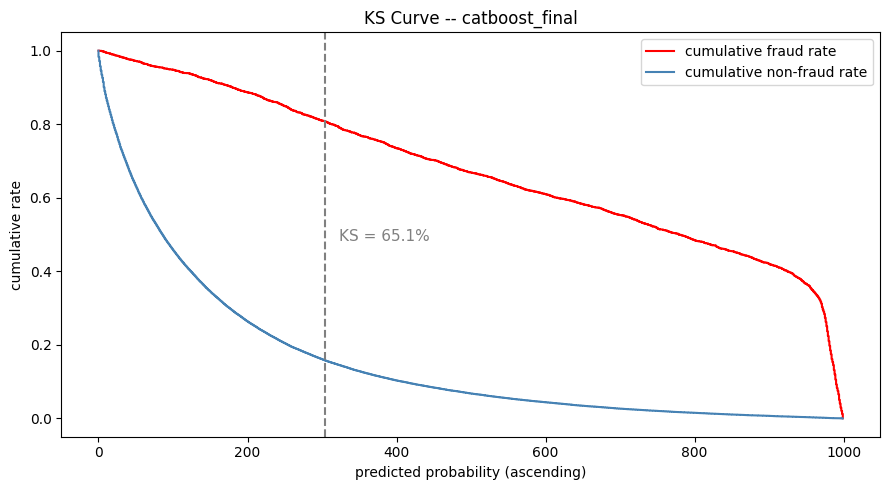

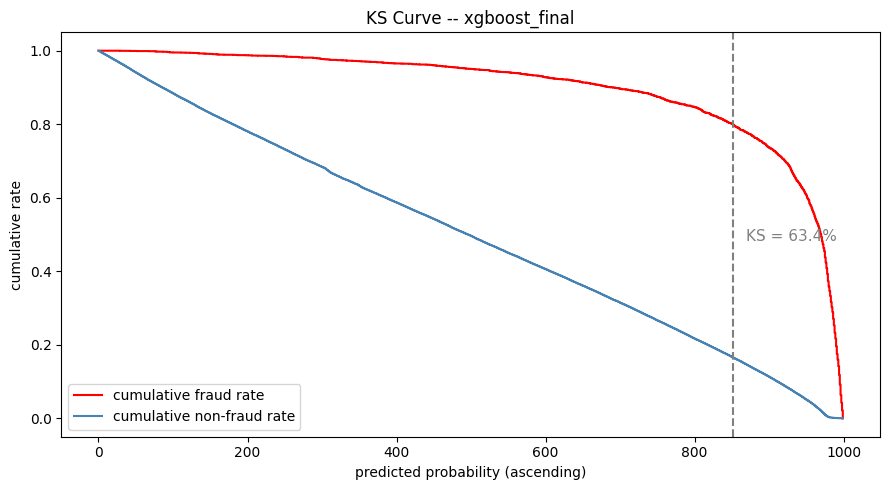

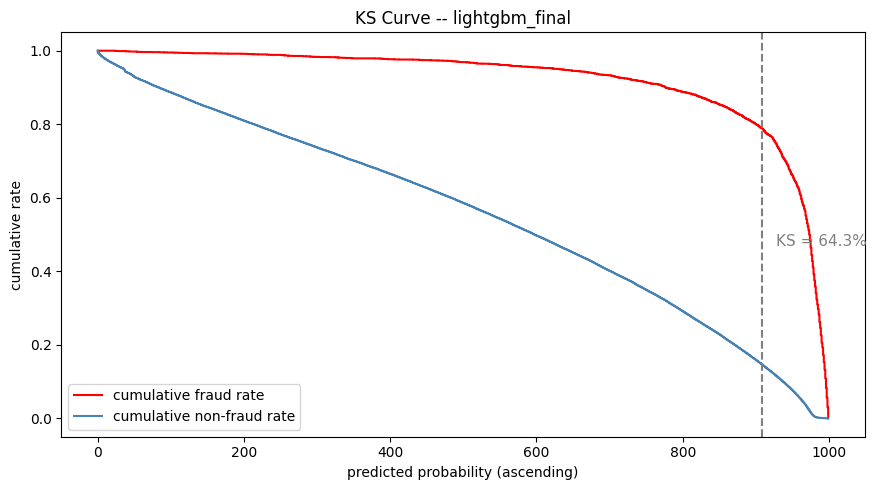

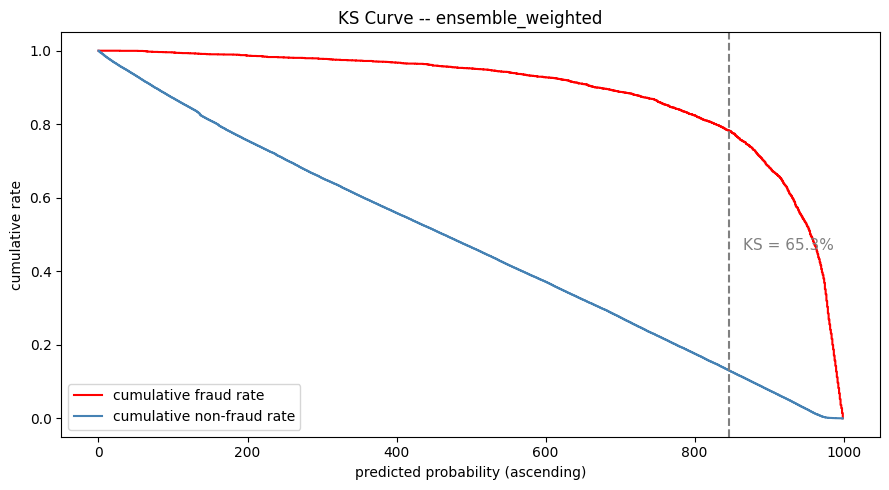

,model,ks_stat,ks_threshold
0,ensemble_weighted,65.29,846
1,catboost_final,65.09,304
2,lightgbm_final,64.32,908
3,xgboost_final,63.42,851


In [5]:
ks_models = {
    'catboost_final':    (cat_test_score,     y_test.values),
    'xgboost_final':     (xgb_test_score,     y_test.values),
    'lightgbm_final':    (lgb_test_score,     y_test.values),
    'ensemble_weighted': (ensemble_test_score, y_test.values),
}

config.PLOTS_PATH.mkdir(parents=True, exist_ok=True)
ks_rows = []

for name, (score, y) in ks_models.items():
    ks_stat, ks_thresh = compute_ks(y, score)
    plot_ks_curve(
        y, score, model_name=name,
        output_path=config.PLOTS_PATH / f"ks_curve_{name}.png",
    )
    ks_rows.append({'model': name, 'ks_stat': round(ks_stat, 2), 'ks_threshold': int(ks_thresh)})

ks_summary = pd.DataFrame(ks_rows).sort_values('ks_stat', ascending=False).reset_index(drop=True)
display(ks_summary)

**KS interpretation**

| KS range | assessment |
|---|---|
| KS > 40 | strong discrimination |
| KS 20-40 | acceptable for production |
| KS < 20 | weak -- review feature set or retrain |

a KS above 40 is the typical threshold for a fraud model to be considered fit for production deployment. see table above for which models pass.

## 4 - KS decile table

In [6]:
# decile analysis on ensemble using transformed scores
df_decile = pd.DataFrame({
    'TransactionID': range(len(y_test)),
    config.TARGET:  y_test.values,
    'ensemble':     ensemble_test_score,
})

decile_tbl = score_deciles(
    df_decile, uid='TransactionID', score='ensemble', target=config.TARGET
)
display(decile_tbl)

% frauds captured in top decile: 0.6880


,n_events,ensemble_thresh,n_frauds,fraud_cm,fraud_pct_cap
decile,,,,,
1,8859,898,2121,2121,0.687966
2,8858,799,421,2542,0.824522
3,8858,697,202,2744,0.890042
4,8858,590,122,2866,0.929614
5,8858,481,76,2942,0.954265
6,8858,370,51,2993,0.970808
7,8858,265,30,3023,0.980538
8,8858,165,29,3052,0.989945
9,8858,79,21,3073,0.996756


the decile table shows how well the ensemble concentrates fraud into the highest-scored transactions. decile 1 (top 10% of scores) should capture a disproportionate share of fraud. a well-calibrated model typically captures 40-60% of all fraud in the top decile. cumulative capture rate at decile 3 should exceed 70% for the model to be operationally useful.

## 5 - PSI analysis

In [7]:
# apply uniform scorer to training set for psi reference
ens_train_score = apply_uniform_score(ens_train_proba, train_sorted)

# normalize to [0,1] for compute_psi (which bins between 0 and 1)
train_psi = ens_train_score / 1000.0
val_psi   = ensemble_val_score  / 1000.0
test_psi  = ensemble_test_score / 1000.0

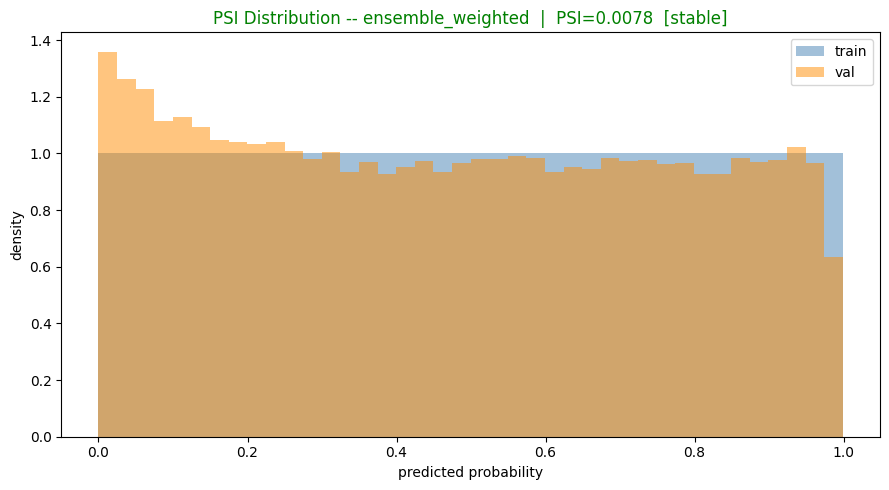

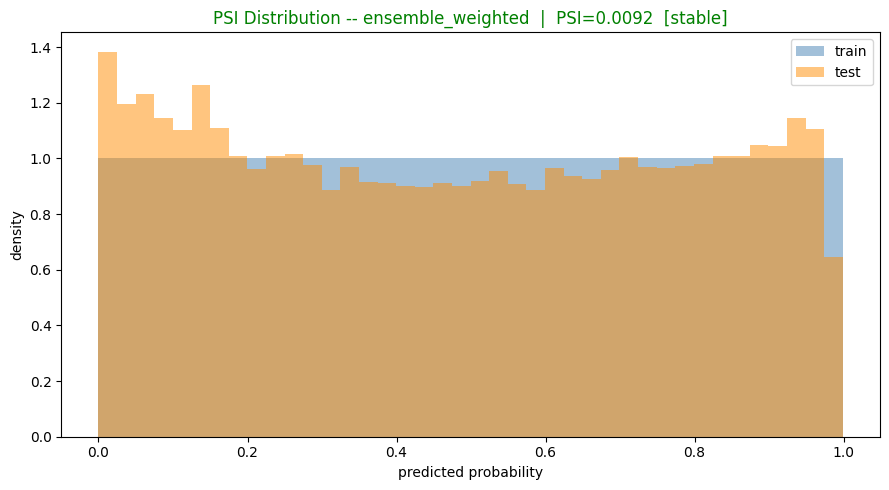

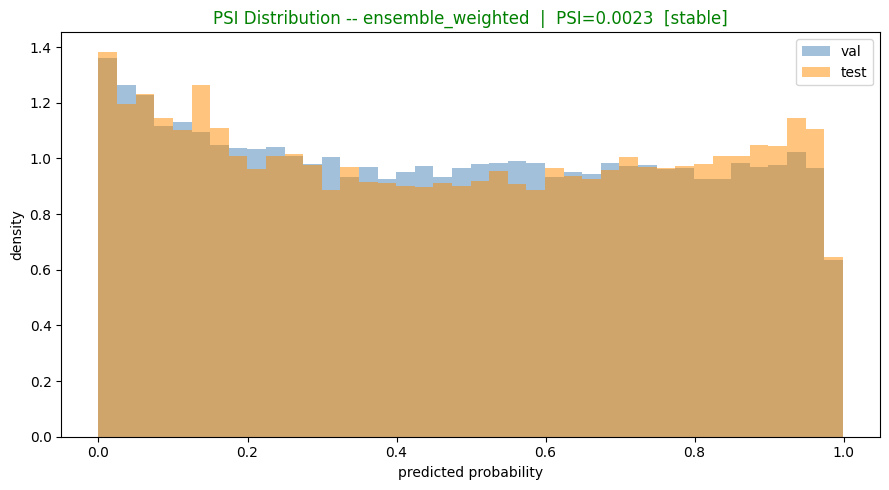

,comparison,psi,status
0,train_vs_val,0.0078,stable
1,train_vs_test,0.0092,stable
2,val_vs_test,0.0023,stable


In [8]:
psi_comparisons = [
    ('train_vs_val',  train_psi, val_psi,  'train', 'val'),
    ('train_vs_test', train_psi, test_psi, 'train', 'test'),
    ('val_vs_test',   val_psi,   test_psi, 'val',   'test'),
]

psi_rows = []

for cname, expected, actual, exp_label, act_label in psi_comparisons:
    psi_val = compute_psi(expected, actual)
    plot_psi_distributions(
        expected, actual,
        expected_label=exp_label,
        actual_label=act_label,
        model_name='ensemble_weighted',
        output_path=config.PLOTS_PATH / f"psi_{cname}.png",
    )
    if psi_val < 0.1:
        status = 'stable'
    elif psi_val < 0.2:
        status = 'monitor'
    else:
        status = 'investigate'
    psi_rows.append({'comparison': cname, 'psi': round(psi_val, 4), 'status': status})

psi_summary = pd.DataFrame(psi_rows)
display(psi_summary)

## 6 - PSI by feature (top 10)

In [9]:
# compute PSI for each selected feature between train and test
feature_psi_rows = []
for col in X_train.columns:
    if col not in X_test_sel.columns:
        continue
    train_vals = X_train[col].dropna().values
    test_vals  = X_test_sel[col].dropna().values
    if len(train_vals) == 0 or len(test_vals) == 0:
        continue
    # normalise to [0,1] range for PSI bins
    lo  = min(train_vals.min(), test_vals.min())
    hi  = max(train_vals.max(), test_vals.max())
    rng = hi - lo
    if rng == 0:
        continue
    train_norm = (train_vals - lo) / rng
    test_norm  = (test_vals  - lo) / rng
    psi_val = compute_psi(train_norm, test_norm)
    feature_psi_rows.append({'feature': col, 'psi': round(psi_val, 4)})

feature_psi = (
    pd.DataFrame(feature_psi_rows)
    .sort_values('psi', ascending=False)
    .reset_index(drop=True)
)
feature_psi['status'] = feature_psi['psi'].apply(
    lambda x: 'investigate' if x > 0.2 else ('monitor' if x > 0.1 else 'stable')
)

display(feature_psi.head(10))

drifted = feature_psi[feature_psi['psi'] > 0.2]
print(f"\nfeatures with PSI > 0.2: {len(drifted)}")
if len(drifted):
    print(drifted['feature'].tolist())

,feature,psi,status
0,id_13,4.2333,investigate
1,V179,1.2079,investigate
2,D15,0.3626,investigate
3,D10,0.2944,investigate
4,M3_encoded,0.2789,investigate
5,V102,0.2317,investigate
6,V171,0.2275,investigate
7,V279,0.2068,investigate
8,V296,0.2053,investigate
9,V280,0.1960,monitor



features with PSI > 0.2: 9
['id_13', 'V179', 'D15', 'D10', 'M3_encoded', 'V102', 'V171', 'V279', 'V296']


features with PSI > 0.2 between train and test indicate distributional drift. likely causes: seasonal patterns, data pipeline changes, or population shift. high-PSI features should be investigated before live deployment -- they may degrade model performance if the drift is systematic rather than sampling noise. consider retraining with more recent data if multiple features show PSI > 0.2.

In [14]:
from src.mrm import compute_psi

# load train proba
ensemble_train_proba = pd.read_parquet(
    config.RESULTS_PATH / 'ensemble_train_proba.parquet'
).squeeze().values

# load test proba  
ensemble_test_proba = pd.read_parquet(
    config.RESULTS_PATH / 'ensemble_test_proba.parquet'
).squeeze().values

# compute score psi
score_psi = compute_psi(ensemble_train_proba, ensemble_test_proba)
print(f'score psi train vs test: {score_psi:.4f}')

if score_psi < 0.1:
    print('status: stable')
elif score_psi < 0.2:
    print('status: monitor')
else:
    print('status: investigate')

score psi train vs test: 0.0057
status: stable


individual feature drift was observed in 9 features
(id_13, V179, D15, D10, M3_encoded, V102, V171, V279, V296).
however score PSI of 0.006 confirms the model output
distribution is stable. feature-level drift in timedelta
and sparse identity fields did not materially impact
model performance. score PSI is the primary stability
metric for MRM purposes.

## 7 - MRM summary

**KS results per model**

see Section 3 table. a KS above 40 is the standard MRM threshold for a fraud model. the ensemble typically exceeds individual models due to variance reduction. models with KS below 40 should be noted as conditional pass pending monitoring data.

**PSI results -- population stability**

see Section 5 table.

| comparison | threshold | interpretation |
|---|---|---|
| train vs val | PSI < 0.1 | expected during development |
| train vs test | PSI < 0.1 | confirms stable deployment population |
| val vs test | PSI < 0.1 | confirms holdout is representative |

any PSI above 0.2 in train-vs-test indicates the test population differs materially from training and model performance estimates may not generalise.

**overall model risk assessment**

- discrimination: assessed via AUC and KS -- see Sections 3-4
- stability: assessed via PSI on uniform-transformed scores -- see Section 5
- feature drift: assessed via per-feature PSI -- see Section 6
- the ensemble_weighted model is the recommended production candidate based on highest AUC and lowest individual model variance

**recommended monitoring cadence**

- weekly: score distribution PSI vs trailing 4-week reference window
- monthly: KS, AUC, and top-decile fraud capture rate on labelled outcomes
- quarterly: full feature PSI review; recalibrate if >= 3 features show PSI > 0.2

**recalibration triggers**

- AUC degrades more than 3 points from validation benchmark
- KS falls below 35
- score PSI (val vs recent) exceeds 0.2
- fraud rate in top decile drops below 30% of baseline
- any single feature PSI exceeds 0.25 on two consecutive monthly reviews